# Linear static analysis

This example computes the displacement, strain and stress fields of a laminated plate under a transverse pressure, for the five models of `panels` that the example compares, and checks them against the Navier solutions of Reddy (1984) and the three-dimensional elasticity solution of Pagano (1970).

A `Shell` object describes a plate or a cylindrical shell through its attributes: the geometry, the laminate, the number of terms `m` and `n` of the approximation functions and the model, by default `'plate_clpt_donnell'` for plates and `'cylshell_clpt_sanders'` for cylindrical shells; see `panels.models` for the other models. The displacements are Ritz series, each term a product of a function of $x$ and a function of $y$. These functions are the Legendre-based hierarchical functions of Bardell (1991), in the form of Castro and Donadon (2017), see [Bardell's functions](../bardell.rst). Minimizing the total potential energy with respect to the Ritz constants $\boldsymbol{c}$ gives the linear system

$$
\boldsymbol{K}_C \boldsymbol{c} = \boldsymbol{F}_{ext},
$$

where $\boldsymbol{K}_C$ is the constitutive stiffness matrix, `Shell.calc_kC`, and $\boldsymbol{F}_{ext}$ the external force vector, `Shell.calc_fext`. The system is solved with `structsolve.solve`, and the fields are recovered from $\boldsymbol{c}$ with `Shell.uvw`, `Shell.strain` and `Shell.stress`.

In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Markdown, display
from structsolve import solve
from panels.shell import Shell


def results_table(rows):
    """Markdown table of (quantity, panels, reference, source) rows"""
    out = ['| quantity | panels | reference | relative difference | reference source |',
           '|---|---|---|---|---|']
    for name, val, ref, src in rows:
        out.append('| %s | %.6g | %.6g | %+.2e | %s |'
                   % (name, val, ref, (val - ref)/abs(ref), src))
    display(Markdown('\n'.join(out)))

## Plate, laminate, boundary conditions and load

The case is Problem 2 of Reddy (1984): a rectangular plate with $b = 3a$, of three layers $[0/90/0]$ of equal thickness $h/3$, the fibres of the outer layers along $x$, under the sinusoidal pressure

$$
q(x, y) = q_0 \sin\frac{\pi x}{a} \sin\frac{\pi y}{b},
$$

with the lamina properties of Reddy's Eq. (27), $E_1 = 25 \times 10^6$ psi, $E_2 = 10^6$ psi, $G_{12} = G_{13} = 0.5 \times 10^6$ psi, $G_{23} = 0.2 \times 10^6$ psi, $\nu_{12} = 0.25$. They are given in psi and the lengths in inches; the normalized results below do not depend on the units nor on $a$. The material is given by `laminaprop` $= (E_{11}, E_{22}, \nu_{12}, G_{12}, G_{13}, G_{23})$. The load is a callable passed to `Shell.add_pressure_load`.

The plate is simply supported. Reddy's Navier solution, his Eq. (20), takes $w \propto \sin\alpha x \sin\beta y$, $\psi_x \propto \cos\alpha x \sin\beta y$ and $\psi_y \propto \sin\alpha x \cos\beta y$: $w$ and the rotation tangential to the edge vanish at the edges, the normal rotation is free. For this symmetric laminate the in-plane displacements are uncoupled from the bending; here the tangential displacement is constrained and the normal one is free (the hard simple support). The boundary conditions are the flags `x1u`, `x1ur`, `x2u`, ..., `y2wr`: `0` constrains and `1` releases the translation (e.g. `x1u`) or the rotation (e.g. `x1ur`) of each displacement component at the edges $x = 0$ (`x1`), $x = a$ (`x2`), $y = 0$ (`y1`) and $y = b$ (`y2`). The models based on shear deformation theories have the rotations as independent fields, with the analogous flags `x1phix`, `x1phixr`, ..., `y2phiyr`.

Reddy's first-order shear deformation theory (FSDT) results use the shear correction factors $k_1^2 = k_2^2 = 5/6$ (footnote b of his Table 2); the same value is given to `Shell.fsdt_shear_correction`, a float that multiplies the transverse shear stiffness.

In [2]:
E1, E2, NU12, G12, G13, G23 = 25e6, 1e6, 0.25, 0.5e6, 0.5e6, 0.2e6  # psi
Q0 = 1.  # psi
A = 10.  # in


def build_plate(model, S, m=12, n=12):
    """Plate (or nearly flat cylindrical shell) of length a = A and a/h = S"""
    h = A/S
    s = Shell(model=model, a=A, b=3*A, m=m, n=n, stack=[0, 90, 0], plyt=h/3,
              laminaprop=(E1, E2, NU12, G12, G13, G23),
              r=1.e8*A if model.startswith('cylshell') else None)
    s.fsdt_shear_correction = 5/6
    for edge in ('x1', 'x2', 'y1', 'y2'):
        x_edge = edge.startswith('x')
        for field in ('u', 'v', 'w', 'phix', 'phiy'):
            setattr(s, edge + field, 1.)
            setattr(s, edge + field + 'r', 1.)
        setattr(s, edge + ('v' if x_edge else 'u'), 0.)
        setattr(s, edge + 'w', 0.)
        setattr(s, edge + ('phiy' if x_edge else 'phix'), 0.)
    s.add_pressure_load(lambda x, y: Q0*np.sin(np.pi*x/s.a)*np.sin(np.pi*y/s.b))
    return s


s = build_plate('plate_clpt_donnell', S=10)
print('number of Ritz constants:', s.get_size())

number of Ritz constants: 432


## Solving the linear system and recovering the stresses

`Shell.strain` gives the generalized strains of the model: the membrane strains $\varepsilon^{(0)} = (\varepsilon_{xx}, \varepsilon_{yy}, \gamma_{xy})$ and the curvatures $\kappa^{(1)} = (\kappa_{xx}, \kappa_{yy}, \kappa_{xy})$, plus, for the third-order theory (TSDT), the cubic terms $\kappa^{(3)}$ (`kxx3`, `kyy3`, `kxy3`). The in-plane strains at a thickness coordinate $z$ are

$$
\varepsilon(z) = \varepsilon^{(0)} + z\,\kappa^{(1)} + z^3 \kappa^{(3)},
$$

and the stresses of a ply follow from its plane-stress reduced stiffnesses, here of the $0^\circ$ ply at the top face, $\sigma_{xx} = Q_{11}\varepsilon_{xx} + Q_{12}\varepsilon_{yy}$ and $\tau_{xy} = Q_{66}\gamma_{xy}$, with $Q_{11} = E_1/(1 - \nu_{12}\nu_{21})$, $Q_{12} = \nu_{12}E_2/(1 - \nu_{12}\nu_{21})$, $Q_{66} = G_{12}$ and $\nu_{21} = \nu_{12}E_2/E_1$.

The quantities are normalized as in Reddy (1984), Table 1:

$$
\bar{w} = \frac{100\, w(a/2, b/2) E_2 h^3}{q_0 a^4}, \qquad
\bar\sigma_1 = \sigma_{xx}\left(\frac{a}{2}, \frac{b}{2}, \frac{h}{2}\right)\frac{h^2}{q_0 a^2}, \qquad
\bar\sigma_6 = \tau_{xy}\left(0, 0, \frac{h}{2}\right)\frac{h^2}{q_0 a^2}.
$$

The footnote of Table 1 prints the factor of $\bar w$ as 10; the ordinate of Reddy's Fig. 3, "$\times 10^2$", and the values of the tables, reproduced below, correspond to 100, the factor of Pagano (1970), Eq. (39).

In [3]:
NU21 = NU12*E2/E1
Q11 = E1/(1 - NU12*NU21)
Q12 = NU12*E2/(1 - NU12*NU21)
Q66 = G12


def normalized(s, c, S):
    """(w_bar, sigma_1_bar, sigma_6_bar) of Reddy (1984), Table 1"""
    a, b, h = s.a, s.b, s.a/S
    w = s.uvw(c, xs=np.array([a/2]), ys=np.array([b/2]))[1]['w'][0]
    f = s.strain(c, xs=np.array([a/2, 0.]), ys=np.array([b/2, 0.]))[1]
    z = h/2
    eps = {}
    for e, k in (('exx', 'kxx'), ('eyy', 'kyy'), ('gxy', 'kxy')):
        eps[e] = f[e] + z*f[k] + (z**3*f[k + '3'] if k + '3' in f else 0.)
    sxx = Q11*eps['exx'][0] + Q12*eps['eyy'][0]
    txy = Q66*eps['gxy'][1]
    return (100*w*E2*h**3/(Q0*a**4), sxx*h**2/(Q0*a**2), txy*h**2/(Q0*a**2))


c = solve(s.calc_kC(), s.calc_fext(), silent=True)
print('CLPT, a/h = 10: w_bar = %.4f, sigma_1_bar = %.4f, sigma_6_bar = %.5f'
      % normalized(s, c, 10))

CLPT, a/h = 10: w_bar = 0.5034, sigma_1_bar = 0.6233, sigma_6_bar = -0.00828


## Fields

The deflection $w$ follows the load, a half sine wave in each direction. The bending moment $M_{xx}$ is largest at the center, and the twisting moment $M_{xy}$ at the corners, where the stress $\tau_{xy}$ of $\bar\sigma_6$ is evaluated:

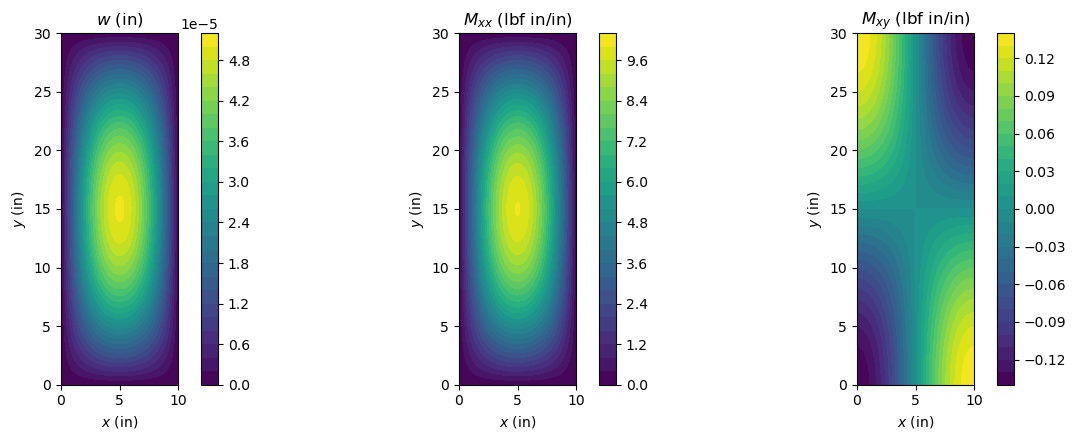

In [4]:
mesh, fields = s.uvw(c)
X, Y, w = mesh['Xs'], mesh['Ys'], fields['w'].copy()
_, fields = s.stress(c)
Mxx, Mxy = fields['Mxx'].copy(), fields['Mxy'].copy()
fig, axes = plt.subplots(1, 3, figsize=(13, 4.5))
for ax, field, title in zip(axes, (w, Mxx, Mxy),
                            ('$w$ (in)', '$M_{xx}$ (lbf in/in)',
                             '$M_{xy}$ (lbf in/in)')):
    cf = ax.contourf(X, Y, field, levels=30, cmap='viridis')
    fig.colorbar(cf, ax=ax)
    ax.set_title(title)
    ax.set_xlabel('$x$ (in)')
    ax.set_ylabel('$y$ (in)')
    ax.set_aspect('equal')
fig.tight_layout()
plt.show()

## The five models

The same plate is solved with the classical laminated plate theory (CLPT) for a plate and for cylindrical shells with Donnell's and Sanders' kinematics, the shell models with a large radius $r = 10^8 a$, with the FSDT and with the TSDT for plates, for $a/h = 10$ and $a/h = 100$. Each model is compared with the column of the same theory in Reddy (1984), Table 2: the classical plate theory (CPT), given in the block $a/h = 100$, for the CLPT models (its normalized values do not depend on $a/h$), "FSDT" for the FSDT and "Present", Reddy's third-order theory, for the TSDT. The sign of $\tau_{xy}$ at the corner depends on the orientation of $z$ relative to the load; the magnitude of $\bar\sigma_6$ is compared.

In [5]:
# Reddy (1984), Table 2, (w_bar, sigma_1_bar, sigma_6_bar)
REDDY_T2 = {
    10: {'Pagano': (0.919, 0.725, 0.0123), 'Present': (0.8622, 0.6924, 0.0115),
         'FSDT': (0.803, 0.6214, 0.0105)},
    100: {'Pagano': (0.508, 0.624, 0.0083), 'Present': (0.507, 0.624, 0.0083),
          'FSDT': (0.5064, 0.6233, 0.0083)},
}
REDDY_CPT = (0.503, 0.623, 0.0083)
COLUMN = {'clpt': 'CPT', 'fsdt': 'FSDT', 'tsdt': 'Present'}
NAMES = (r'$\bar w$', r'$\bar\sigma_1$', r'$|\bar\sigma_6|$')
MODELS = ['plate_clpt_donnell', 'cylshell_clpt_donnell', 'cylshell_clpt_sanders',
          'plate_fsdt_donnell', 'plate_tsdt_donnell']

results = {}
rows = []
for S in (10, 100):
    for model in MODELS:
        s = build_plate(model, S)
        c = solve(s.calc_kC(), s.calc_fext(), silent=True)
        values = normalized(s, c, S)
        values = (values[0], values[1], abs(values[2]))
        results[model, S] = values
        print('a/h = %3d, %-22s w_bar %.4f, sigma_1_bar %.4f, |sigma_6_bar| %.5f'
              % ((S, model) + values))
        column = COLUMN[model.split('_')[1]]
        ref = REDDY_CPT if column == 'CPT' else REDDY_T2[S][column]
        for name, val, r in zip(NAMES, values, ref):
            rows.append(('$a/h = %d$, `%s`: %s' % (S, model, name), val, r,
                         'Reddy (1984), Table 2, %s' % column))
results_table(rows)

a/h =  10, plate_clpt_donnell     w_bar 0.5034, sigma_1_bar 0.6233, |sigma_6_bar| 0.00828
a/h =  10, cylshell_clpt_donnell  w_bar 0.5034, sigma_1_bar 0.6233, |sigma_6_bar| 0.00828


a/h =  10, cylshell_clpt_sanders  w_bar 0.5034, sigma_1_bar 0.6233, |sigma_6_bar| 0.00828


a/h =  10, plate_fsdt_donnell     w_bar 0.8030, sigma_1_bar 0.6214, |sigma_6_bar| 0.01048


a/h =  10, plate_tsdt_donnell     w_bar 0.8622, sigma_1_bar 0.6924, |sigma_6_bar| 0.01151
a/h = 100, plate_clpt_donnell     w_bar 0.5034, sigma_1_bar 0.6233, |sigma_6_bar| 0.00828


a/h = 100, cylshell_clpt_donnell  w_bar 0.5034, sigma_1_bar 0.6233, |sigma_6_bar| 0.00828
a/h = 100, cylshell_clpt_sanders  w_bar 0.5034, sigma_1_bar 0.6233, |sigma_6_bar| 0.00828


a/h = 100, plate_fsdt_donnell     w_bar 0.5064, sigma_1_bar 0.6233, |sigma_6_bar| 0.00830
a/h = 100, plate_tsdt_donnell     w_bar 0.5070, sigma_1_bar 0.6240, |sigma_6_bar| 0.00831


| quantity | panels | reference | relative difference | reference source |
|---|---|---|---|---|
| $a/h = 10$, `plate_clpt_donnell`: $\bar w$ | 0.503382 | 0.503 | +7.59e-04 | Reddy (1984), Table 2, CPT |
| $a/h = 10$, `plate_clpt_donnell`: $\bar\sigma_1$ | 0.623271 | 0.623 | +4.34e-04 | Reddy (1984), Table 2, CPT |
| $a/h = 10$, `plate_clpt_donnell`: $|\bar\sigma_6|$ | 0.0082803 | 0.0083 | -2.37e-03 | Reddy (1984), Table 2, CPT |
| $a/h = 10$, `cylshell_clpt_donnell`: $\bar w$ | 0.503382 | 0.503 | +7.59e-04 | Reddy (1984), Table 2, CPT |
| $a/h = 10$, `cylshell_clpt_donnell`: $\bar\sigma_1$ | 0.623271 | 0.623 | +4.34e-04 | Reddy (1984), Table 2, CPT |
| $a/h = 10$, `cylshell_clpt_donnell`: $|\bar\sigma_6|$ | 0.0082803 | 0.0083 | -2.37e-03 | Reddy (1984), Table 2, CPT |
| $a/h = 10$, `cylshell_clpt_sanders`: $\bar w$ | 0.503382 | 0.503 | +7.59e-04 | Reddy (1984), Table 2, CPT |
| $a/h = 10$, `cylshell_clpt_sanders`: $\bar\sigma_1$ | 0.623271 | 0.623 | +4.34e-04 | Reddy (1984), Table 2, CPT |
| $a/h = 10$, `cylshell_clpt_sanders`: $|\bar\sigma_6|$ | 0.0082803 | 0.0083 | -2.37e-03 | Reddy (1984), Table 2, CPT |
| $a/h = 10$, `plate_fsdt_donnell`: $\bar w$ | 0.803011 | 0.803 | +1.36e-05 | Reddy (1984), Table 2, FSDT |
| $a/h = 10$, `plate_fsdt_donnell`: $\bar\sigma_1$ | 0.621417 | 0.6214 | +2.78e-05 | Reddy (1984), Table 2, FSDT |
| $a/h = 10$, `plate_fsdt_donnell`: $|\bar\sigma_6|$ | 0.0104795 | 0.0105 | -1.95e-03 | Reddy (1984), Table 2, FSDT |
| $a/h = 10$, `plate_tsdt_donnell`: $\bar w$ | 0.86219 | 0.8622 | -1.20e-05 | Reddy (1984), Table 2, Present |
| $a/h = 10$, `plate_tsdt_donnell`: $\bar\sigma_1$ | 0.692351 | 0.6924 | -7.00e-05 | Reddy (1984), Table 2, Present |
| $a/h = 10$, `plate_tsdt_donnell`: $|\bar\sigma_6|$ | 0.01151 | 0.0115 | +8.74e-04 | Reddy (1984), Table 2, Present |
| $a/h = 100$, `plate_clpt_donnell`: $\bar w$ | 0.503382 | 0.503 | +7.59e-04 | Reddy (1984), Table 2, CPT |
| $a/h = 100$, `plate_clpt_donnell`: $\bar\sigma_1$ | 0.623271 | 0.623 | +4.34e-04 | Reddy (1984), Table 2, CPT |
| $a/h = 100$, `plate_clpt_donnell`: $|\bar\sigma_6|$ | 0.0082803 | 0.0083 | -2.37e-03 | Reddy (1984), Table 2, CPT |
| $a/h = 100$, `cylshell_clpt_donnell`: $\bar w$ | 0.503382 | 0.503 | +7.59e-04 | Reddy (1984), Table 2, CPT |
| $a/h = 100$, `cylshell_clpt_donnell`: $\bar\sigma_1$ | 0.623271 | 0.623 | +4.34e-04 | Reddy (1984), Table 2, CPT |
| $a/h = 100$, `cylshell_clpt_donnell`: $|\bar\sigma_6|$ | 0.00828029 | 0.0083 | -2.37e-03 | Reddy (1984), Table 2, CPT |
| $a/h = 100$, `cylshell_clpt_sanders`: $\bar w$ | 0.503382 | 0.503 | +7.59e-04 | Reddy (1984), Table 2, CPT |
| $a/h = 100$, `cylshell_clpt_sanders`: $\bar\sigma_1$ | 0.623271 | 0.623 | +4.34e-04 | Reddy (1984), Table 2, CPT |
| $a/h = 100$, `cylshell_clpt_sanders`: $|\bar\sigma_6|$ | 0.00828029 | 0.0083 | -2.37e-03 | Reddy (1984), Table 2, CPT |
| $a/h = 100$, `plate_fsdt_donnell`: $\bar w$ | 0.506383 | 0.5064 | -3.41e-05 | Reddy (1984), Table 2, FSDT |
| $a/h = 100$, `plate_fsdt_donnell`: $\bar\sigma_1$ | 0.623252 | 0.6233 | -7.77e-05 | Reddy (1984), Table 2, FSDT |
| $a/h = 100$, `plate_fsdt_donnell`: $|\bar\sigma_6|$ | 0.00830283 | 0.0083 | +3.41e-04 | Reddy (1984), Table 2, FSDT |
| $a/h = 100$, `plate_tsdt_donnell`: $\bar w$ | 0.507004 | 0.507 | +8.17e-06 | Reddy (1984), Table 2, Present |
| $a/h = 100$, `plate_tsdt_donnell`: $\bar\sigma_1$ | 0.623968 | 0.624 | -5.20e-05 | Reddy (1984), Table 2, Present |
| $a/h = 100$, `plate_tsdt_donnell`: $|\bar\sigma_6|$ | 0.00831334 | 0.0083 | +1.61e-03 | Reddy (1984), Table 2, Present |

The three CLPT models give the same values: with $r = 10^8 a$ the curvature terms of the shell kinematics vanish. Each model reproduces the Navier solution of its own theory within the last printed digit, which shows that the Ritz series of $12 \times 12$ terms has converged and that the boundary conditions are those of the Navier solution.

## Shear deformation and the elasticity solution

The theories differ in how they represent the transverse shear deformation. The CLPT neglects it, and its normalized values are those of a very thin plate. The FSDT assumes a constant shear strain through the thickness, corrected by $k^2 = 5/6$, and the TSDT a parabolic one, which vanishes at the faces. Compared with the three-dimensional elasticity solution of Pagano (1970), also listed in Reddy's Table 2, the error of each theory at $a/h = 10$ is:

In [6]:
rows = []
for model in ('plate_clpt_donnell', 'plate_fsdt_donnell', 'plate_tsdt_donnell'):
    for S in (10, 100):
        for name, val, r in zip(NAMES, results[model, S], REDDY_T2[S]['Pagano']):
            rows.append(('$a/h = %d$, `%s`: %s' % (S, model, name), val, r,
                         'Pagano (1970), in Reddy (1984), Table 2'))
results_table(rows)

| quantity | panels | reference | relative difference | reference source |
|---|---|---|---|---|
| $a/h = 10$, `plate_clpt_donnell`: $\bar w$ | 0.503382 | 0.919 | -4.52e-01 | Pagano (1970), in Reddy (1984), Table 2 |
| $a/h = 10$, `plate_clpt_donnell`: $\bar\sigma_1$ | 0.623271 | 0.725 | -1.40e-01 | Pagano (1970), in Reddy (1984), Table 2 |
| $a/h = 10$, `plate_clpt_donnell`: $|\bar\sigma_6|$ | 0.0082803 | 0.0123 | -3.27e-01 | Pagano (1970), in Reddy (1984), Table 2 |
| $a/h = 100$, `plate_clpt_donnell`: $\bar w$ | 0.503382 | 0.508 | -9.09e-03 | Pagano (1970), in Reddy (1984), Table 2 |
| $a/h = 100$, `plate_clpt_donnell`: $\bar\sigma_1$ | 0.623271 | 0.624 | -1.17e-03 | Pagano (1970), in Reddy (1984), Table 2 |
| $a/h = 100$, `plate_clpt_donnell`: $|\bar\sigma_6|$ | 0.0082803 | 0.0083 | -2.37e-03 | Pagano (1970), in Reddy (1984), Table 2 |
| $a/h = 10$, `plate_fsdt_donnell`: $\bar w$ | 0.803011 | 0.919 | -1.26e-01 | Pagano (1970), in Reddy (1984), Table 2 |
| $a/h = 10$, `plate_fsdt_donnell`: $\bar\sigma_1$ | 0.621417 | 0.725 | -1.43e-01 | Pagano (1970), in Reddy (1984), Table 2 |
| $a/h = 10$, `plate_fsdt_donnell`: $|\bar\sigma_6|$ | 0.0104795 | 0.0123 | -1.48e-01 | Pagano (1970), in Reddy (1984), Table 2 |
| $a/h = 100$, `plate_fsdt_donnell`: $\bar w$ | 0.506383 | 0.508 | -3.18e-03 | Pagano (1970), in Reddy (1984), Table 2 |
| $a/h = 100$, `plate_fsdt_donnell`: $\bar\sigma_1$ | 0.623252 | 0.624 | -1.20e-03 | Pagano (1970), in Reddy (1984), Table 2 |
| $a/h = 100$, `plate_fsdt_donnell`: $|\bar\sigma_6|$ | 0.00830283 | 0.0083 | +3.41e-04 | Pagano (1970), in Reddy (1984), Table 2 |
| $a/h = 10$, `plate_tsdt_donnell`: $\bar w$ | 0.86219 | 0.919 | -6.18e-02 | Pagano (1970), in Reddy (1984), Table 2 |
| $a/h = 10$, `plate_tsdt_donnell`: $\bar\sigma_1$ | 0.692351 | 0.725 | -4.50e-02 | Pagano (1970), in Reddy (1984), Table 2 |
| $a/h = 10$, `plate_tsdt_donnell`: $|\bar\sigma_6|$ | 0.01151 | 0.0123 | -6.42e-02 | Pagano (1970), in Reddy (1984), Table 2 |
| $a/h = 100$, `plate_tsdt_donnell`: $\bar w$ | 0.507004 | 0.508 | -1.96e-03 | Pagano (1970), in Reddy (1984), Table 2 |
| $a/h = 100$, `plate_tsdt_donnell`: $\bar\sigma_1$ | 0.623968 | 0.624 | -5.20e-05 | Pagano (1970), in Reddy (1984), Table 2 |
| $a/h = 100$, `plate_tsdt_donnell`: $|\bar\sigma_6|$ | 0.00831334 | 0.0083 | +1.61e-03 | Pagano (1970), in Reddy (1984), Table 2 |

At $a/h = 100$ the three theories agree with the elasticity solution within about 1%. At $a/h = 10$ the CLPT underestimates the deflection by about 45%, the FSDT by about 13% and the TSDT by about 6%. The TSDT also gives the closest stresses; the $ar\sigma_1$ of the FSDT is no closer than that of the CLPT, since in both theories the in-plane strains are linear in $z$. These differences are those of the theories, not of the Ritz discretization, since each model agrees with the Navier solution of its own theory.

## References

1. N. S. Bardell, "Free vibration analysis of a flat plate using the hierarchical finite element method". Journal of Sound and Vibration, 151(2):263-289, 1991. https://doi.org/10.1016/0022-460X(91)90855-E.
2. S. G. P. Castro and M. V. Donadon, "Assembly of semi-analytical models to address linear buckling and vibration of stiffened composite panels with debonding defect". Composite Structures, 160:232-247, 2017. https://doi.org/10.1016/j.compstruct.2016.10.026.
3. N. J. Pagano, "Exact solutions for rectangular bidirectional composites and sandwich plates". Journal of Composite Materials, 4(1):20-34, 1970. https://doi.org/10.1177/002199837000400102.
4. J. N. Reddy, "A simple higher-order theory for laminated composite plates". Journal of Applied Mechanics, 51(4):745-752, 1984. https://doi.org/10.1115/1.3167719.